In [3]:
!pip -q install librosa soundfile matplotlib numpy

In [4]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

In [12]:
pliki_audio = ['Samogłoska.wav', 'Wyraz.wav', 'Zdanie.wav']

def wczytaj_audio(sciezka=None):
    """Wczytuje audio do 16 kHz mono. Bez pliku zwraca sygnał syntetyczny."""
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

Liczba próbek: 32000
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.00 s


In [21]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13, n_fft=N_FFT, hop_length=HOP_LENGTH):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

In [22]:
def wykresy(y, sr, S_db, M, hop_length, tytul="Analiza sygnału"):
  fig, ax = plt.subplots(3, 1, figsize=(10, 9))
  fig.suptitle(tytul, fontsize=14)

  librosa.display.waveshow(y, sr=sr, ax=ax[0])
  ax[0].set_title("Przebieg czasowy (fala)")

  img1 = librosa.display.specshow(
      S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
      )
  ax[1].set_title("Log-mel spektrogram")
  fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

  img2 = librosa.display.specshow(
      M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
      )
  ax[2].set_title("MFCC")
  fig.colorbar(img2, ax=ax[2])

  plt.tight_layout()
  plt.show()

Przebieg czasowy, log-mel i MFCC


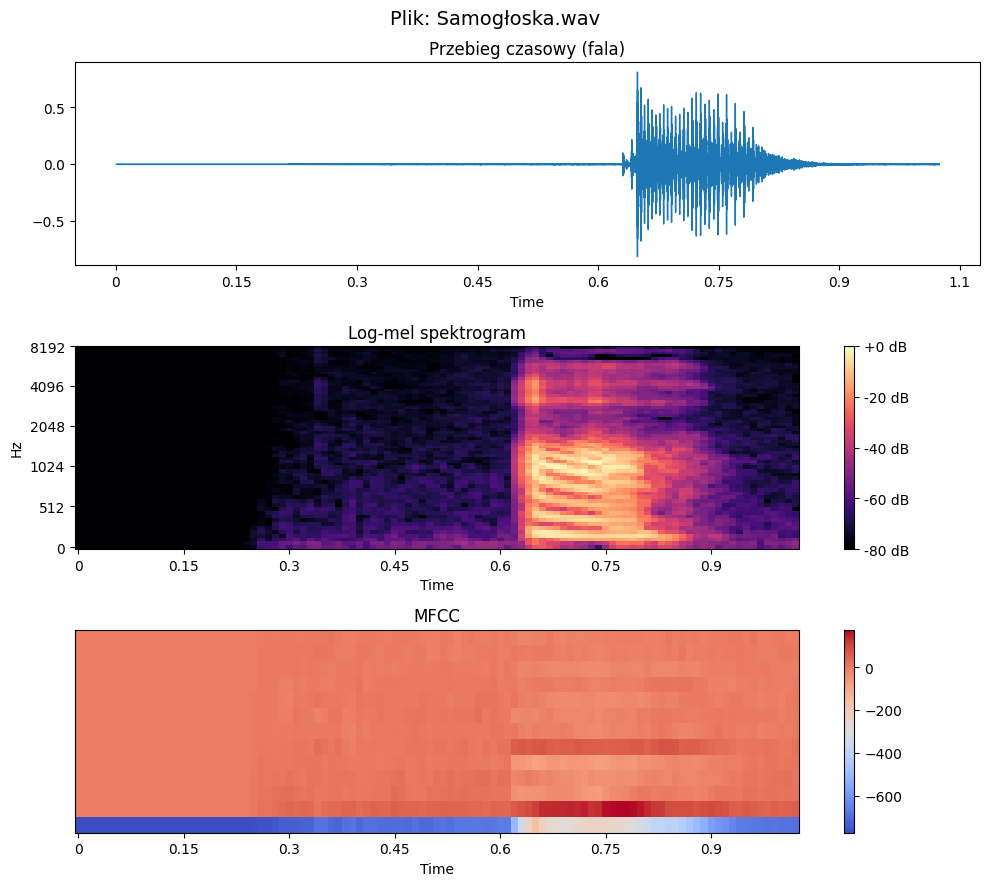

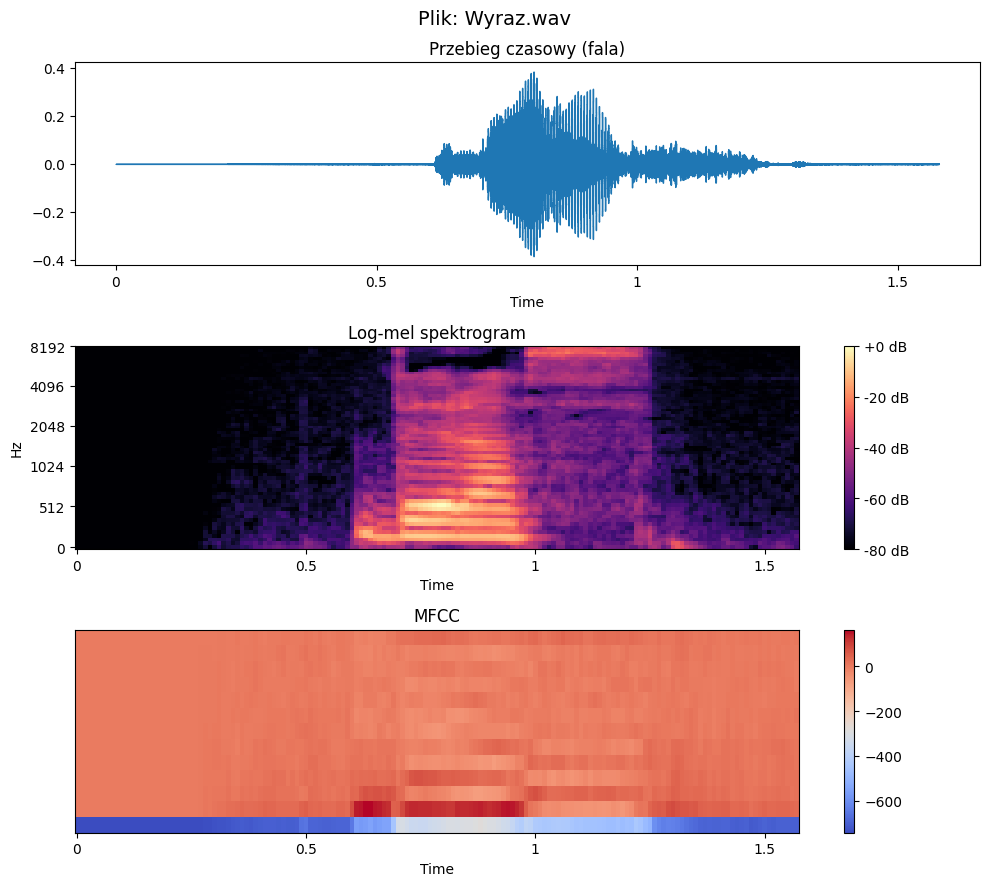

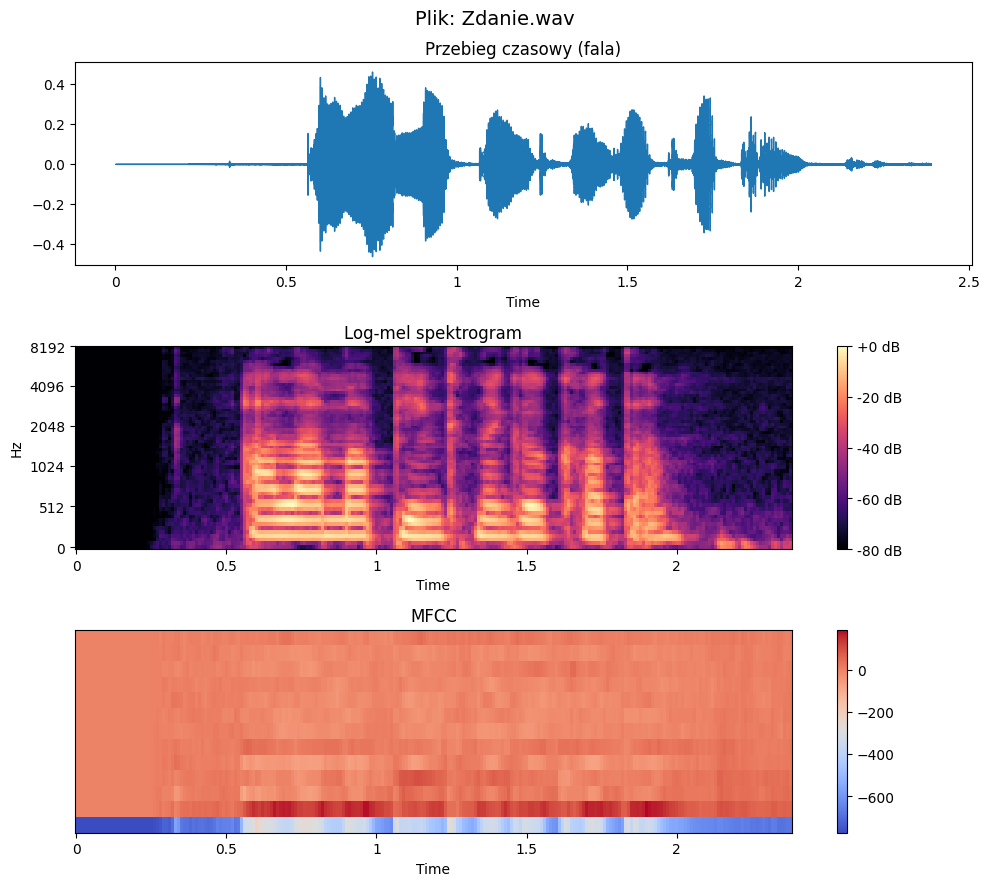

In [41]:
print("Przebieg czasowy, log-mel i MFCC")
for plik in pliki_audio:
    y, sr = wczytaj_audio(plik)
    S_db = log_mel(y, sr)
    M = mfcc(y, sr)
    wykresy(y, sr, S_db, M, HOP_LENGTH, tytul=f"Plik: {plik}")

Badanie wpływu parametrów N_FFT i HOP_LENGTH


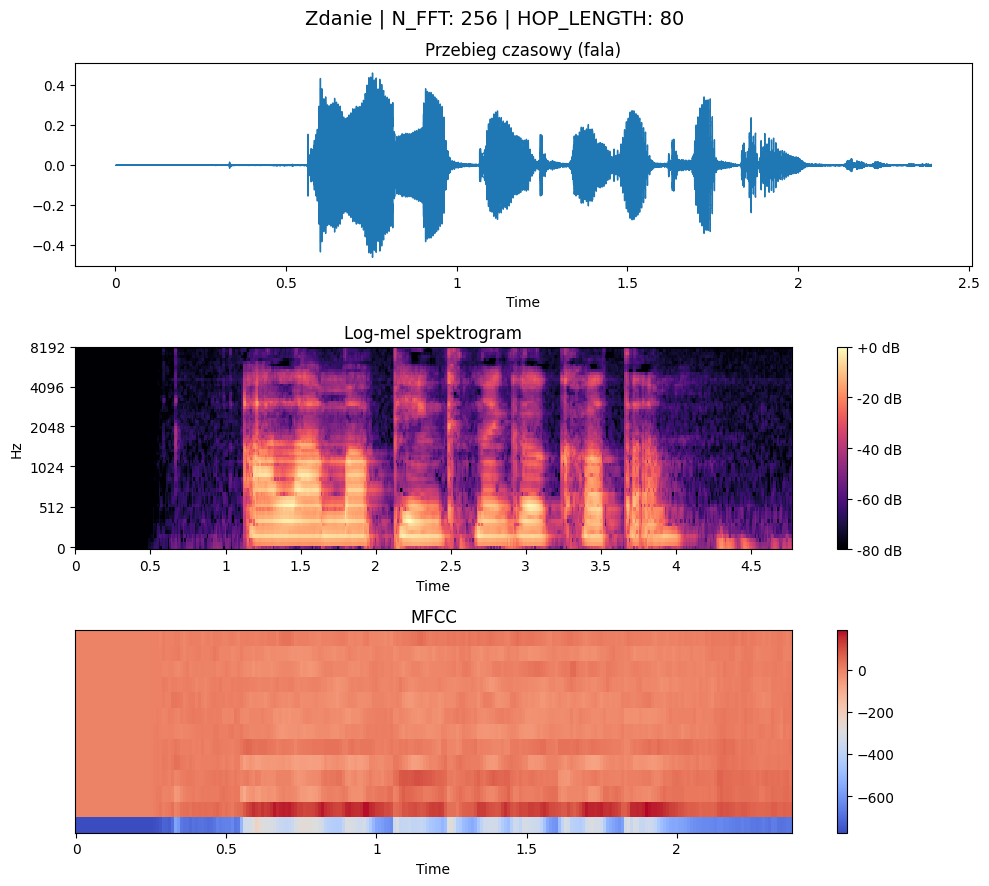

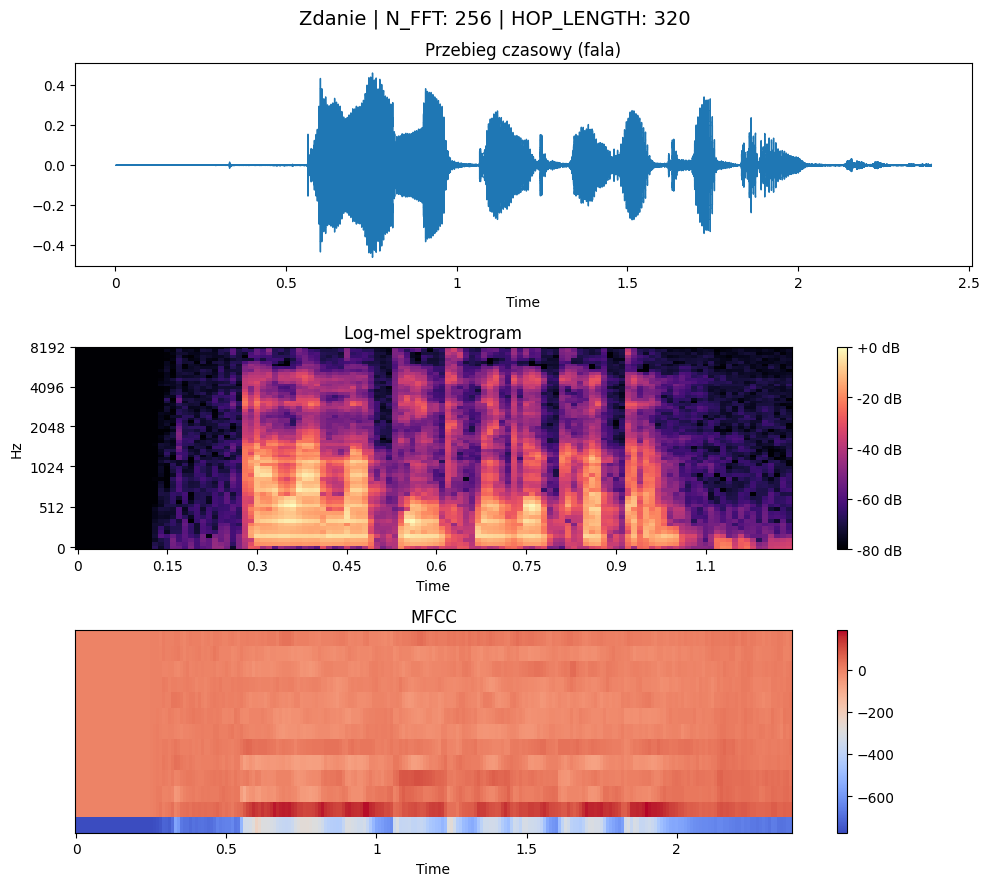

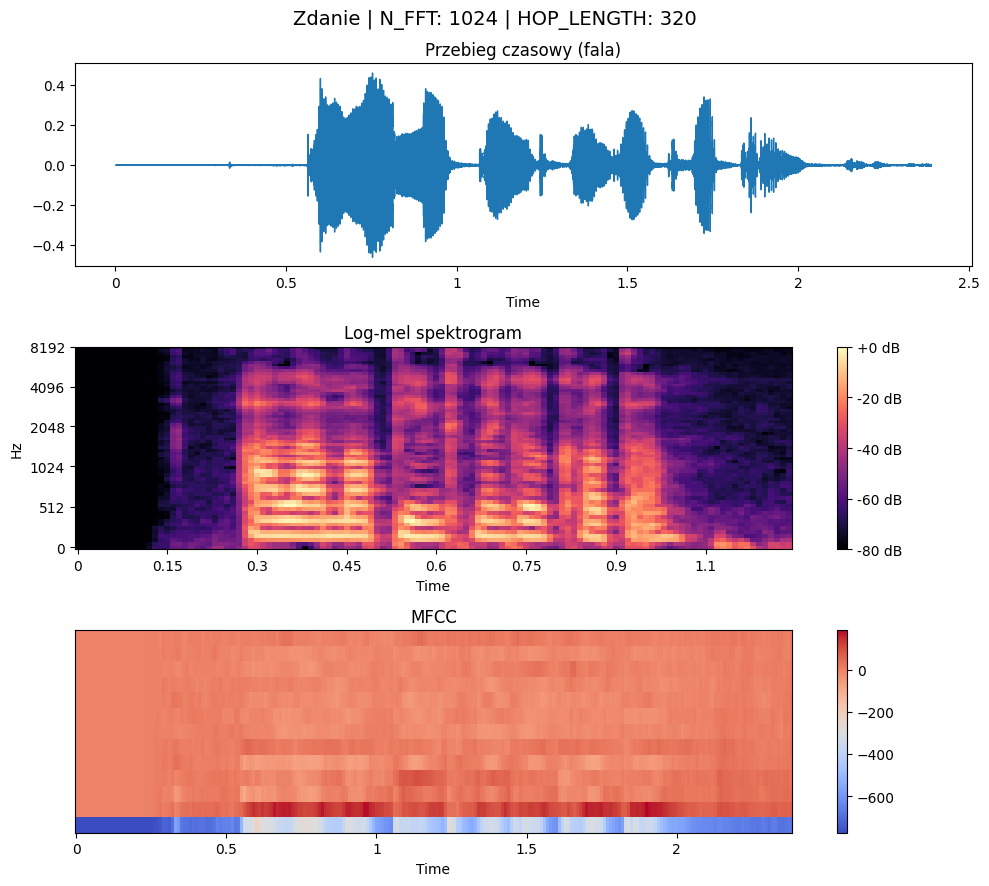

In [40]:
print("Badanie wpływu parametrów N_FFT i HOP_LENGTH")
y_test, sr_test = wczytaj_audio('Zdanie.wav')
S_db_1 = log_mel(y_test, sr_test, n_fft=256, hop_length=80)
M_1 = mfcc(y_test, sr_test, n_fft=256, hop_length=80)
wykresy(y_test, sr_test, S_db_1, M_1, hop_length=80, tytul="Zdanie | N_FFT: 256 | HOP_LENGTH: 80")

S_db_1 = log_mel(y_test, sr_test, n_fft=256, hop_length=320)
M_1 = mfcc(y_test, sr_test, n_fft=256, hop_length=320)
wykresy(y_test, sr_test, S_db_1, M_1, hop_length=320, tytul="Zdanie | N_FFT: 256 | HOP_LENGTH: 320")

S_db_2 = log_mel(y_test, sr_test, n_fft=1024, hop_length=320)
M_2 = mfcc(y_test, sr_test, n_fft=1024, hop_length=320)
wykresy(y_test, sr_test, S_db_2, M_2, hop_length=320, tytul="Zdanie | N_FFT: 1024 | HOP_LENGTH: 320")